# Progressão Aritmética (PA)
### Conceitos, fórmulas e visualizações

Uma **Progressão Aritmética (PA)** é uma sequência numérica em que a diferença entre dois termos consecutivos é constante. Essa diferença recebe o nome de **razão**, representada pela letra \(r\).

A fórmula da razão é:

\[
r = a_{n} - a_{n-1}
\]

Em que \(a_n\) representa um termo e \(a_{n-1}\) o termo anterior.

Neste notebook, vamos estudar:
- como identificar a razão de uma PA;
- como diferenciar PAs crescentes, decrescentes e constantes;
- como calcular um termo usando a fórmula do termo geral;
- como calcular a soma dos primeiros termos;
- como interpretar essas ideias em gráficos.

> **Instrução:** execute as células de cima para baixo. Os gráficos são gerados com Matplotlib.

In [1]:
# @title
import matplotlib.pyplot as plt
import numpy as np

# Configurações gerais dos gráficos
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Identificando a razão

Considere a sequência:

\[
(2, 5, 8, 11, 14)
\]

A cada passo, somamos \(3\). Portanto, a razão é:

\[
r = 5 - 2 = 3
\]

Uma PA tem razão constante: se a diferença entre termos consecutivos mudar, a sequência não será uma PA.

In [2]:
# @title
termos = [2, 5, 8, 11, 14]

# Calcula as diferenças entre termos consecutivos
razoes = [termos[i] - termos[i - 1] for i in range(1, len(termos))]

print("Termos:", termos)
print("Diferenças:", razoes)
print("A razão é constante?", all(r == razoes[0] for r in razoes))
print("Razão da PA:", razoes[0])

Termos: [2, 5, 8, 11, 14]
Diferenças: [3, 3, 3, 3]
A razão é constante? True
Razão da PA: 3


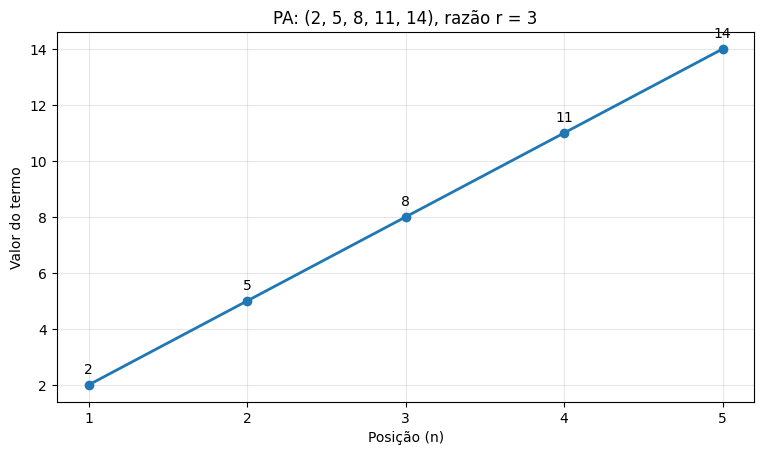

In [3]:
# @title
posicoes = range(1, len(termos) + 1)

plt.figure()
plt.plot(posicoes, termos, marker="o", linewidth=2)
for n, a in zip(posicoes, termos):
    plt.annotate(str(a), (n, a), xytext=(0, 8), textcoords="offset points", ha="center")

plt.xticks(list(posicoes))
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("PA: (2, 5, 8, 11, 14), razão r = 3")
plt.show()

## 2. PA crescente, decrescente e constante

A classificação depende do sinal da razão:

- **Crescente:** \(r > 0\). Os termos aumentam.
- **Decrescente:** \(r < 0\). Os termos diminuem.
- **Constante:** \(r = 0\). Todos os termos são iguais.

Nos gráficos, o eixo horizontal representa a posição do termo e o eixo vertical representa seu valor.

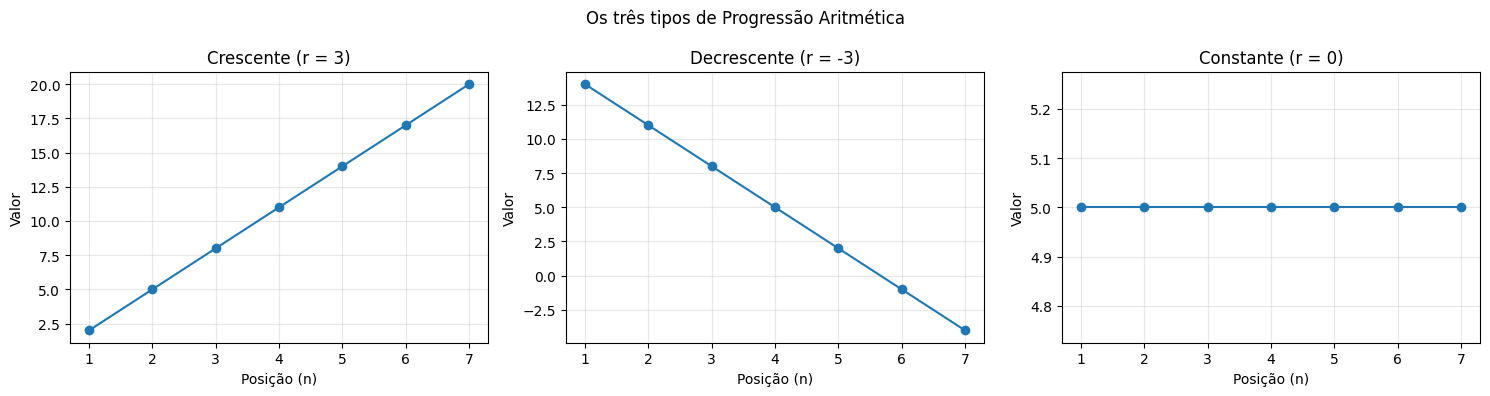

In [4]:
# @title
exemplos = [
    {"nome": "Crescente (r = 3)", "inicio": 2, "razao": 3},
    {"nome": "Decrescente (r = -3)", "inicio": 14, "razao": -3},
    {"nome": "Constante (r = 0)", "inicio": 5, "razao": 0},
]

n = np.arange(1, 8)

fig, eixos = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for ax, exemplo in zip(eixos, exemplos):
    valores = exemplo["inicio"] + (n - 1) * exemplo["razao"]
    ax.plot(n, valores, marker="o")
    ax.set_title(exemplo["nome"])
    ax.set_xlabel("Posição (n)")
    ax.set_ylabel("Valor")
    ax.set_xticks(n)

fig.suptitle("Os três tipos de Progressão Aritmética")
plt.tight_layout()
plt.show()

## 3. Fórmula do termo geral

Para calcular diretamente um termo de uma PA, usamos:

\[
\boxed{a_n = a_1 + (n - 1)r}
\]

- \(a_n\): termo que queremos descobrir;
- \(a_1\): primeiro termo;
- \(n\): posição desejada;
- \(r\): razão.

### Exemplo

Na PA \((3, 7, 11, 15, \ldots)\), qual é o décimo termo?

Temos \(a_1 = 3\), \(r = 4\) e \(n = 10\).

\[
a_{10} = 3 + (10 - 1)\cdot 4 = 39
\]

A fórmula permite chegar ao termo 10 sem precisar listar todos os termos anteriores.

In [5]:
# @title
a1 = 3
r = 4
n_alvo = 10

an = a1 + (n_alvo - 1) * r
print(f"O termo a_{n_alvo} é {an}.")

O termo a_10 é 39.


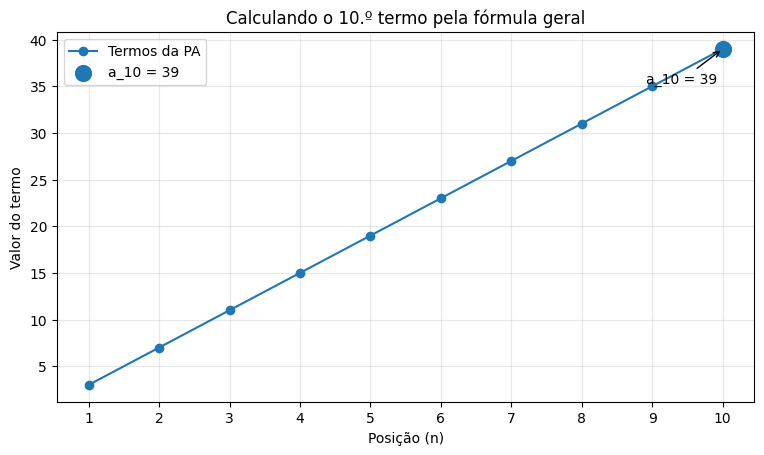

In [6]:
# @title
n = np.arange(1, 11)
valores = a1 + (n - 1) * r

plt.figure()
plt.plot(n, valores, marker="o", label="Termos da PA")
plt.scatter([n_alvo], [an], s=130, label=f"a_{n_alvo} = {an}", zorder=3)
plt.annotate(
    f"a_{n_alvo} = {an}",
    (n_alvo, an),
    xytext=(-55, -25),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)
plt.xticks(n)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("Calculando o 10.º termo pela fórmula geral")
plt.legend()
plt.show()

## 4. Soma dos primeiros termos

A soma dos \(n\) primeiros termos de uma PA pode ser calculada por:

\[
\boxed{S_n = \frac{(a_1 + a_n)n}{2}}
\]

A fórmula usa o primeiro termo, o último termo e a quantidade de termos.

### Exemplo

Para a PA \((2, 4, 6, 8, 10)\):

\[
S_5 = \frac{(2 + 10)\cdot 5}{2} = 30
\]

Também podemos somar os termos um por um. A soma acumulada mostra como o total cresce a cada novo termo.

In [7]:
# @title
a1 = 2
r = 2
quantidade = 5

n = np.arange(1, quantidade + 1)
termos = a1 + (n - 1) * r
somas_acumuladas = np.cumsum(termos)

soma_formula = (termos[0] + termos[-1]) * quantidade / 2

print("Termos:", termos.tolist())
print("Somas acumuladas:", somas_acumuladas.tolist())
print("Soma pela fórmula:", int(soma_formula))
print("Soma direta:", int(sum(termos)))

Termos: [2, 4, 6, 8, 10]
Somas acumuladas: [2, 6, 12, 20, 30]
Soma pela fórmula: 30
Soma direta: 30


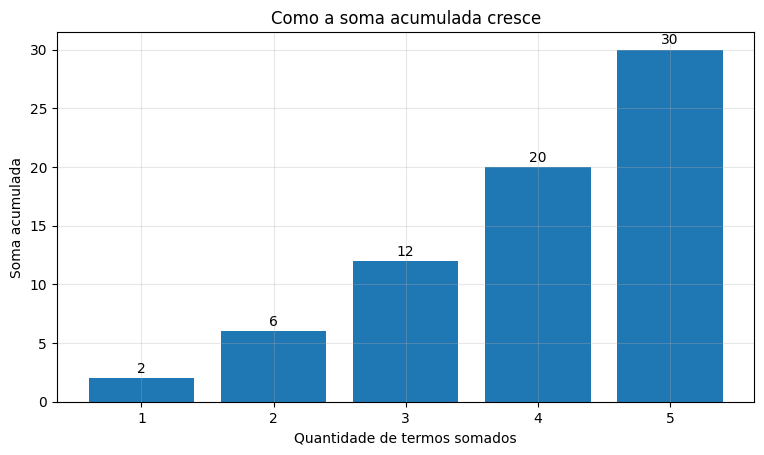

In [8]:
# @title
plt.figure()
plt.bar(n, somas_acumuladas)
for pos, soma in zip(n, somas_acumuladas):
    plt.annotate(str(soma), (pos, soma), xytext=(0, 4),
                 textcoords="offset points", ha="center")

plt.xticks(n)
plt.xlabel("Quantidade de termos somados")
plt.ylabel("Soma acumulada")
plt.title("Como a soma acumulada cresce")
plt.show()

## 5. Exercício prático

Considere a PA:

\[
(5, 9, 13, 17, \ldots)
\]

Antes de executar o código, tente responder:

1. Qual é a razão?
2. Qual é o 8.º termo?
3. Qual é a soma dos 8 primeiros termos?

Use a célula seguinte para conferir os resultados.

In [9]:
# @title
a1 = 5
r = 4
n = 8

an = a1 + (n - 1) * r
soma = (a1 + an) * n / 2
termos = [a1 + i * r for i in range(n)]

print(f"Razão: {r}")
print(f"8.º termo: {an}")
print(f"Soma dos 8 primeiros termos: {int(soma)}")
print("Sequência:", termos)

Razão: 4
8.º termo: 33
Soma dos 8 primeiros termos: 152
Sequência: [5, 9, 13, 17, 21, 25, 29, 33]


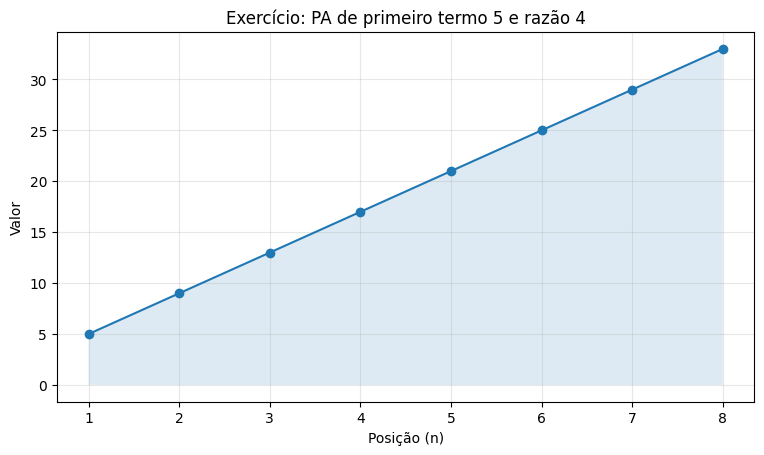

In [10]:
# @title
posicoes = np.arange(1, n + 1)

plt.figure()
plt.plot(posicoes, termos, marker="o")
plt.fill_between(posicoes, termos, alpha=0.15)
plt.xticks(posicoes)
plt.xlabel("Posição (n)")
plt.ylabel("Valor")
plt.title("Exercício: PA de primeiro termo 5 e razão 4")
plt.show()

## 6. Resumo

| Conceito | Fórmula ou condição |
|---|---|
| Razão | \(r = a_n - a_{n-1}\) |
| Termo geral | \(a_n = a_1 + (n-1)r\) |
| Soma dos primeiros \(n\) termos | \(S_n = \frac{(a_1+a_n)n}{2}\) |
| PA crescente | \(r > 0\) |
| PA decrescente | \(r < 0\) |
| PA constante | \(r = 0\) |

**Ideia principal:** em uma PA, a diferença entre termos consecutivos permanece constante. A razão determina se a sequência cresce, diminui ou permanece igual.